# 03 · Visualização — Seca e Cobertura Hídrica (CE / PB · EPSG:31984)

Entradas: `data/processed/` (`reservatorios-ne.geojson`, `municipios-ne.geojson` e os `analise_*.csv` do `02_Analise`).

Visualizações:
1. Mapa de nível dos reservatórios (cor = % capacidade)
2. Série temporal de volume armazenado nas bacias do CE e PB
3. Gráfico de barras: municípios mais críticos por bacia
4. Scatter: pop. rural × distância a reservatório
5. Mapa de bolhas: tamanho = população; cor = % estoque hídrico

**Cores:** o % de capacidade usa a mesma escala nos gráficos 1 e 5 — vermelho = crítico (abaixo de 30%), cinza = faixa intermediária, azul = estoque confortável. As faixas e o limiar de 30% são fixos.

In [1]:
import numpy as np, pandas as pd, geopandas as gpd, matplotlib.pyplot as plt, matplotlib.dates as mdates
from pathlib import Path
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

P = Path("../data/processed")
res = gpd.read_file(P / "reservatorios-ne.geojson")
mun = gpd.read_file(P / "municipios-ne.geojson")
bacias = pd.read_csv(P / "analise_bacias.csv")
est = pd.read_csv(P / "analise_municipio_mes.csv", dtype={"cod_mun": str})
munA = pd.read_csv(P / "analise_municipios.csv", dtype={"cod_mun": str})
corr = pd.read_csv(P / "analise_correlacao.csv")
mun["cod_mun"] = mun.cod_mun.astype(str)
res["vol_hm3"] = res.volume_pct / 100 * res.capacidade_hm3
MES = est.mes.max()
LIMIAR = 30

# cores (superfície clara; vermelho↔azul com cinza no meio; categorias: azul e laranja)
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e4e3de", "#fcfcfb"
EDGES = [20, 30, 50, 70]
CLASSES = ["< 20%", "20–30%", "30–50%", "50–70%", "≥ 70%"]
CORES = ["#d03b3b", "#eb8f8b", "#f0efec", "#86b6ef", "#1c5cab"]
CE_C, PB_C = "#2a78d6", "#eb6834"
classe = lambda p: np.digitize(p, EDGES)             # 0..4 ; <30% = classes 0 e 1
cor_pct = lambda p: [CORES[i] for i in classe(p)]
leg_pct = lambda ax, **k: ax.legend(handles=[Patch(fc=c, ec="#b8b7b0", lw=.6, label=l) for c, l in zip(CORES, CLASSES)],
                                    title="% da capacidade", frameon=False, **k)

plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "axes.edgecolor": GRID,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": .6,
    "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.fontsize": 9, "figure.dpi": 110})

def base_map(ax):
    mun.plot(ax=ax, facecolor="#f4f3ef", edgecolor="#d6d5cf", linewidth=.35)
    ax.set_axis_off(); ax.set_aspect("equal")
print("mês de referência:", MES, "| açudes:", res.SAR_ID.nunique(), "| municípios:", len(mun))

mês de referência: 2026-09 | açudes: 279 | municípios: 407


## 1. Mapa de nível dos reservatórios (cor = % capacidade)

Último valor mensal de cada açude, considerando só os que têm medição nos 6 meses mais recentes (os demais estão desatualizados no SAR).

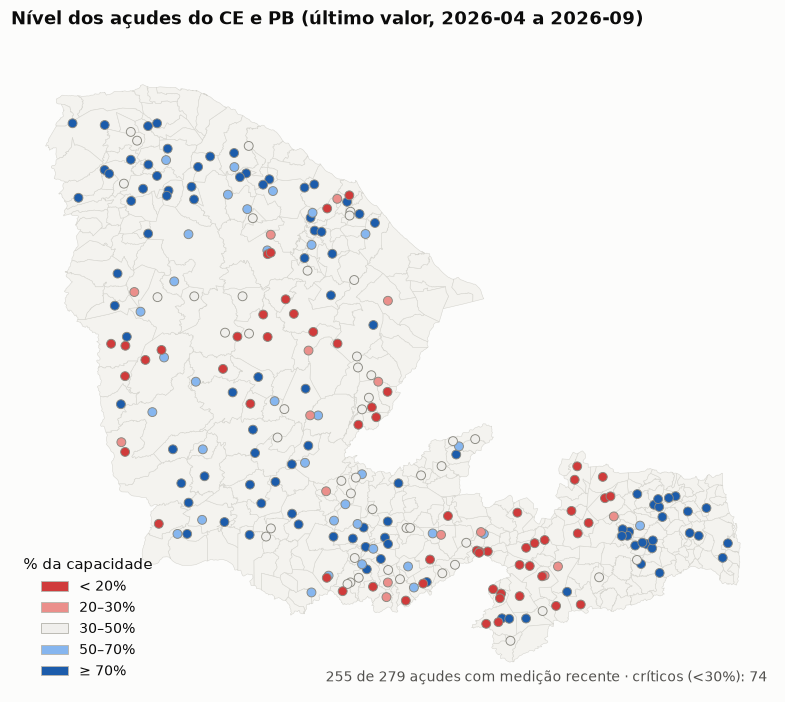

In [2]:
recentes = sorted(res.mes.unique())[-6:]
ult = res.sort_values("mes").groupby("SAR_ID").tail(1)
atual = ult[ult.mes.isin(recentes)].copy()
fig, ax = plt.subplots(figsize=(9.5, 7.5))
base_map(ax)
atual = atual.sort_values("volume_pct", ascending=False)       # críticos por cima
ax.scatter(atual.geometry.x, atual.geometry.y, s=34, c=cor_pct(atual.volume_pct), edgecolor="#8a8981", linewidth=.6, zorder=3)
ax.set_title(f"Nível dos açudes do CE e PB (último valor, {recentes[0]} a {recentes[-1]})", pad=10)
leg_pct(ax, loc="lower left")
ax.text(0.99, 0.01, f"{len(atual)} de {len(ult)} açudes com medição recente · críticos (<30%): {(atual.volume_pct < LIMIAR).sum()}",
        transform=ax.transAxes, ha="right", va="bottom", fontsize=9, color=INK2)
plt.show()

## 2. Série temporal de volume armazenado nas bacias do CE e PB

Volume armazenado (%) = Σ volume ÷ Σ capacidade dos açudes com medição no mês. Linha tracejada = limiar crítico de 30%.

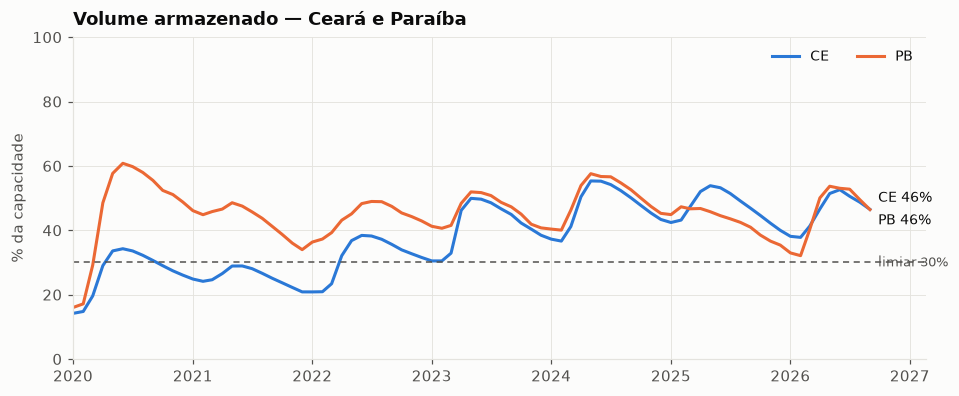

In [3]:
res["data"] = pd.to_datetime(res.mes + "-01")
def serie(df, chave):
    s = df.groupby(chave + ["data"]).agg(v=("vol_hm3", "sum"), c=("capacidade_hm3", "sum")).reset_index()
    s["pct"] = s.v / s.c * 100
    return s

su = serie(res, ["uf"])
fig, ax = plt.subplots(figsize=(10, 3.8))
fim = {}
for uf, c in (("CE", CE_C), ("PB", PB_C)):
    d = su[su.uf == uf]
    ax.plot(d.data, d.pct, color=c, lw=2, label=uf)
    fim[uf] = d.pct.iloc[-1]
ya, yb = sorted(fim.values()); gap = max(0, 7 - (yb - ya))   # afasta rótulos que colidem
pos = {uf: v + (gap / 2 if v == yb else -gap / 2) for uf, v in fim.items()}
for uf in fim:
    ax.text(su.data.max() + pd.Timedelta(days=25), pos[uf], f"{uf} {fim[uf]:.0f}%", color=INK, va="center", fontsize=9)
ax.axhline(LIMIAR, color=INK2, lw=1, ls=(0, (4, 3)))
ax.text(su.data.max() + pd.Timedelta(days=25), LIMIAR, "limiar 30%", color=INK2, va="center", fontsize=8.5)
ax.set_ylim(0, 100); ax.set_ylabel("% da capacidade"); ax.set_xlim(su.data.min(), su.data.max() + pd.Timedelta(days=170))
ax.set_title("Volume armazenado — Ceará e Paraíba", pad=8); ax.legend(frameon=False, loc="upper right", ncol=2)
plt.show()

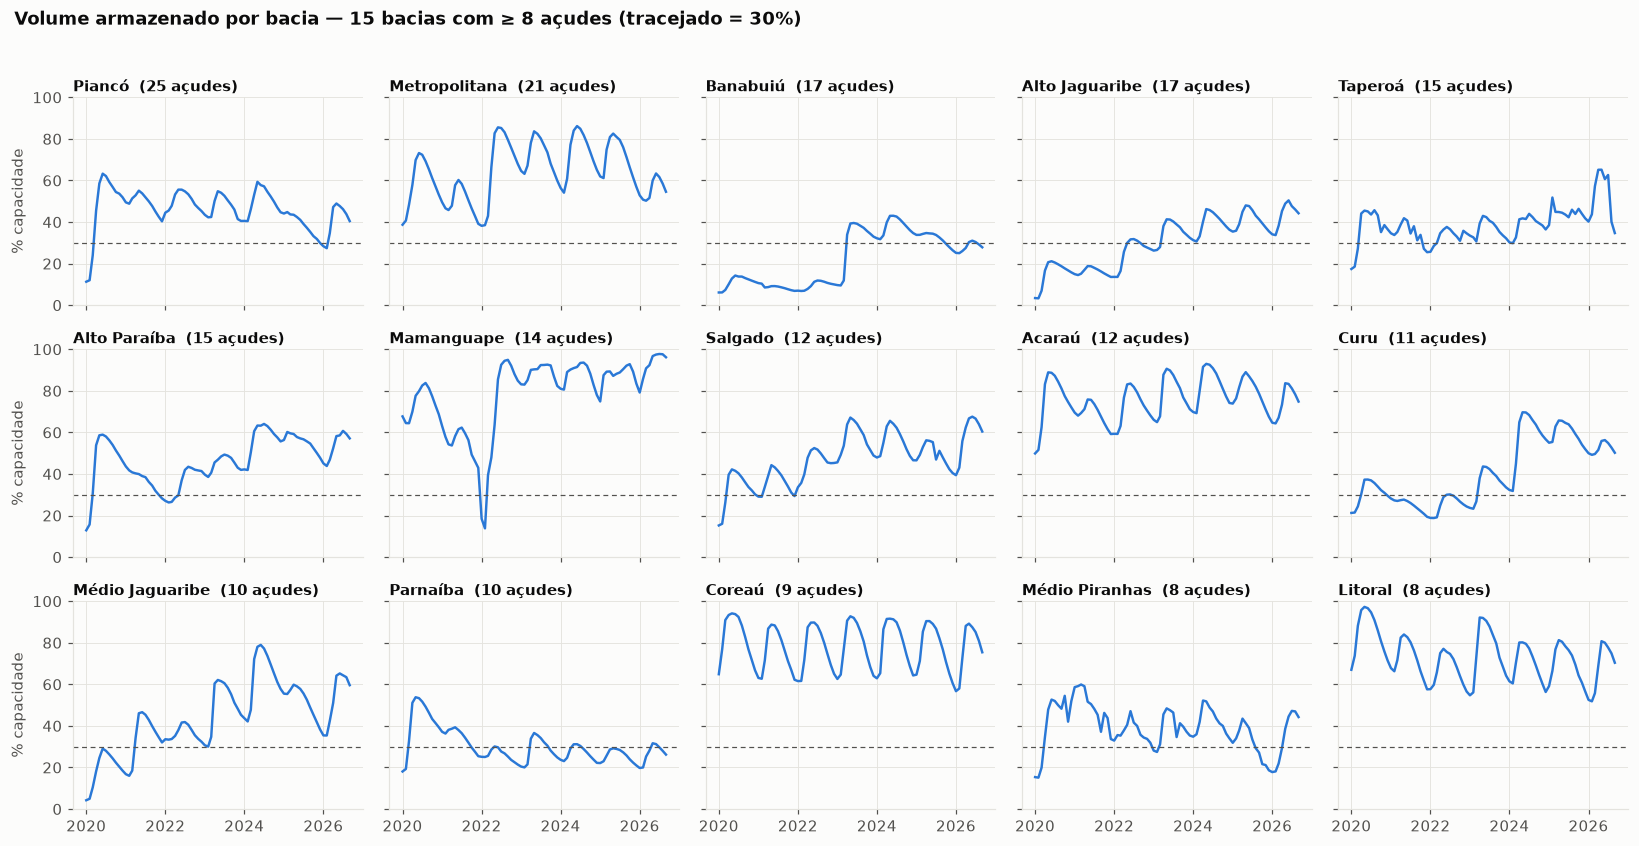

In [4]:
# bacias com pelo menos 8 açudes, um painel por bacia
grandes = bacias[bacias.n_acudes >= 8].sort_values("n_acudes", ascending=False).bacia.tolist()
rb = res.dropna(subset=["bacia"])
sb = serie(rb[rb.bacia.isin(grandes)], ["bacia"])
n = len(grandes); cols = 5; rows = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows, cols, figsize=(15, 2.6 * rows), sharex=True, sharey=True)
for ax, b in zip(axes.flat, grandes):
    d = sb[sb.bacia == b]
    ax.plot(d.data, d.pct, color=CE_C, lw=1.6)
    ax.axhline(LIMIAR, color=INK2, lw=.8, ls=(0, (4, 3)))
    ax.set_title(f"{b.title()}  ({bacias.set_index('bacia').n_acudes[b]} açudes)", fontsize=9.5, pad=4)
    ax.set_ylim(0, 100); ax.xaxis.set_major_locator(mdates.YearLocator(2)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
for ax in list(axes.flat)[n:]: ax.set_visible(False)
for ax in axes[:, 0]: ax.set_ylabel("% capacidade")
fig.suptitle(f"Volume armazenado por bacia — {n} bacias com ≥ 8 açudes (tracejado = 30%)", x=0.012, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, .96)); plt.show()

## 3. Gráfico de barras: municípios mais críticos por bacia

Mês de referência: o mais recente. Um município é crítico quando o estoque hídrico (açudes em 50 km) está abaixo de 30%. À direita, os municípios com menor estoque (empates: maior população rural primeiro).

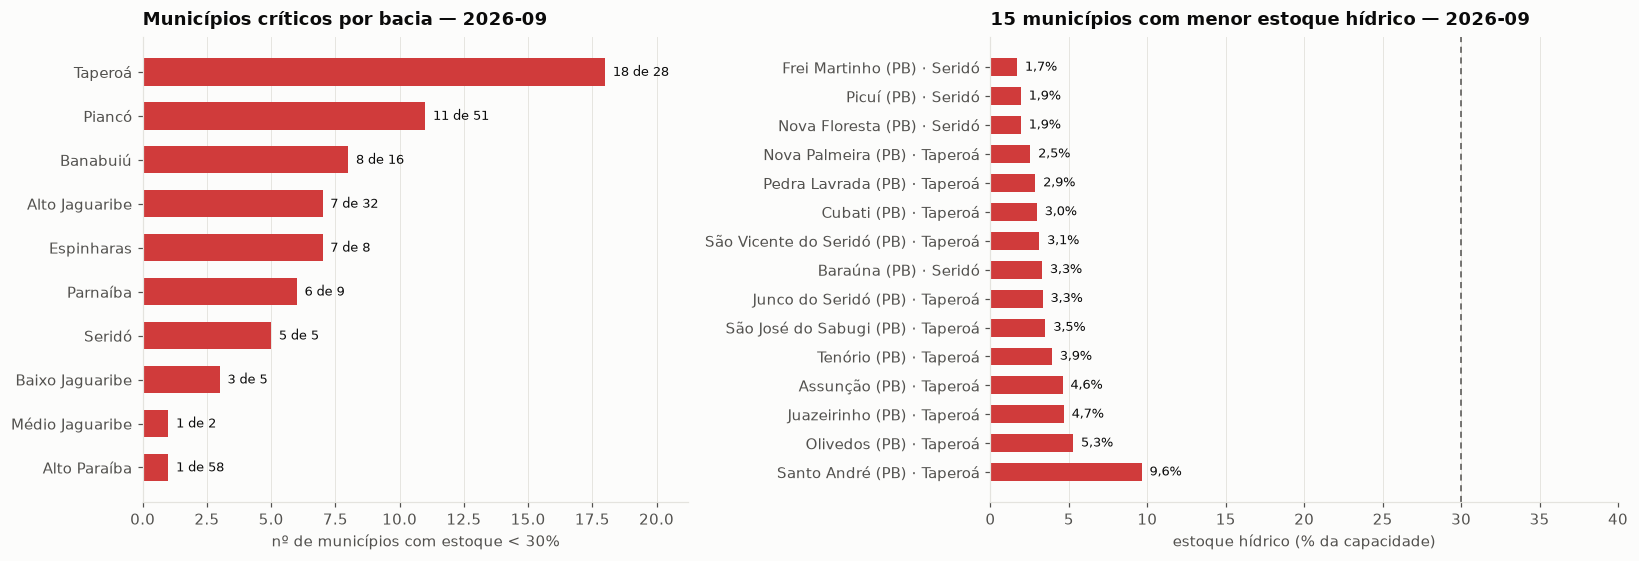

In [5]:
u = est[est.mes == MES]
cb = (u.groupby("bacia").agg(criticos=("critico", "sum"), avaliados=("cod_mun", "nunique"))
        .query("criticos > 0").sort_values("criticos", ascending=True).tail(12))
pior = u.sort_values(["pct_estoque", "pop_rural"], ascending=[True, False]).head(15).iloc[::-1]

fig, (a, b) = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1, 1.15]})
a.barh(cb.index.str.title(), cb.criticos, color="#d03b3b", height=.62)
for y, (k, t) in enumerate(zip(cb.criticos, cb.avaliados)): a.text(k + .3, y, f"{k} de {t}", va="center", fontsize=8.5, color=INK)
a.set_title(f"Municípios críticos por bacia — {MES}", pad=8); a.set_xlabel("nº de municípios com estoque < 30%"); a.grid(axis="y", visible=False)
a.set_xlim(0, cb.criticos.max() * 1.18)
b.barh([f"{r.municipio} ({r.uf}) · {str(r.bacia).title()}" for r in pior.itertuples()], pior.pct_estoque, color="#d03b3b", height=.62)
for y, v in enumerate(pior.pct_estoque): b.text(v + .5, y, f"{v:.1f}%".replace(".", ","), va="center", fontsize=8.5, color=INK)
b.axvline(LIMIAR, color=INK2, lw=1, ls=(0, (4, 3)))
b.set_title(f"15 municípios com menor estoque hídrico — {MES}", pad=8); b.set_xlabel("estoque hídrico (% da capacidade)"); b.grid(axis="y", visible=False)
b.set_xlim(0, 40)
fig.tight_layout(); plt.show()

## 4. Scatter: população rural × distância ao reservatório mais próximo

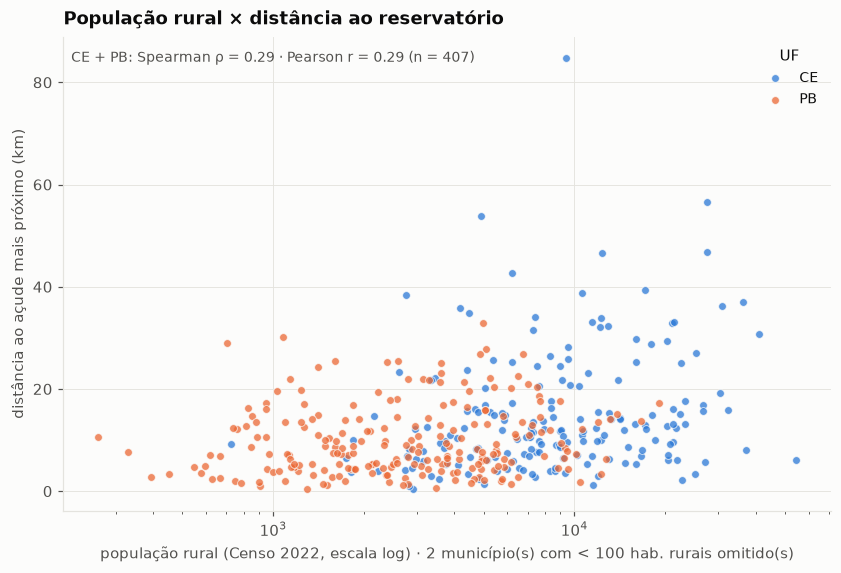

In [6]:
LIM_POP = 100
d = munA[munA.pop_rural >= LIM_POP]                           # escala log: omite pop. rural < 100
fig, ax = plt.subplots(figsize=(9, 5.6))
for uf, c in (("CE", CE_C), ("PB", PB_C)):
    g = d[d.uf == uf]
    ax.scatter(g.pop_rural, g.dist_km, s=26, color=c, alpha=.75, edgecolor=SURF, linewidth=.6, label=uf)
ax.set_xscale("log"); ax.set_xlabel(f"população rural (Censo 2022, escala log) · {(munA.pop_rural < LIM_POP).sum()} município(s) com < {LIM_POP} hab. rurais omitido(s)"); ax.set_ylabel("distância ao açude mais próximo (km)")
ax.set_title("População rural × distância ao reservatório", pad=8); ax.legend(frameon=False, title="UF")
r = corr[corr.recorte == "CE + PB"].iloc[0]
ax.text(.01, .97, f"CE + PB: Spearman ρ = {r.spearman_rho:.2f} · Pearson r = {r.pearson_r:.2f} (n = {int(r.n)})", transform=ax.transAxes, ha="left", va="top", fontsize=9, color=INK2)
plt.show()

## 5. Mapa de bolhas: tamanho = população rural; cor = % estoque hídrico

Bolha no centroide de cada município. Tamanho = população rural (Censo 2022); cor = estoque hídrico no mês de referência (mesma escala do mapa 1). Cinza vazado = município sem açude num raio de 50 km.

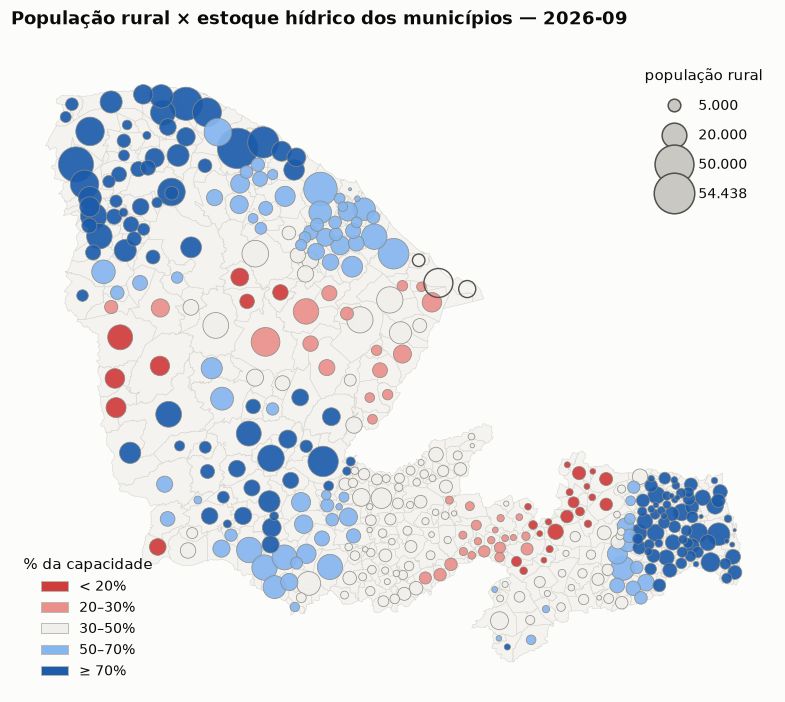

In [7]:
cm = mun.copy(); cm["geometry"] = mun.centroid
cm = cm.merge(est.loc[est.mes == MES, ["cod_mun", "pct_estoque"]], on="cod_mun", how="left").sort_values("pop_rural", ascending=False)
tem = cm.pct_estoque.notna()
K = 700 / cm.pop_rural.max()                                   # área da bolha proporcional à população
fig, ax = plt.subplots(figsize=(9.5, 7.5))
base_map(ax)
ax.scatter(cm.geometry.x[tem], cm.geometry.y[tem], s=cm.pop_rural[tem] * K + 4, c=cor_pct(cm.pct_estoque[tem]),
           edgecolor="#8a8981", linewidth=.5, alpha=.92, zorder=3)
ax.scatter(cm.geometry.x[~tem], cm.geometry.y[~tem], s=cm.pop_rural[~tem] * K + 4, facecolor="none", edgecolor=INK2, linewidth=.9, zorder=3)
ax.set_title(f"População rural × estoque hídrico dos municípios — {MES}", pad=10)
l1 = leg_pct(ax, loc="lower left"); ax.add_artist(l1)
ref = [v for v in (5_000, 20_000, 50_000) if v < cm.pop_rural.max()] + [int(cm.pop_rural.max())]
ax.legend(handles=[Line2D([], [], marker="o", ls="", mfc="#c9c8c2", mec=INK2, ms=np.sqrt(v * K + 4), label=f"{v:,}".replace(",", ".")) for v in ref],
          title="população rural", frameon=False, loc="upper right", labelspacing=1.1)
plt.show()